# ASCENT 4-130, Module 4 : Techniques d'optimisation pour les agents

**Jour 2, première séquence (2 heures).** Programmation sous contraintes et recuit simulé, appliqués au fil rouge de la formation : un robot autonome dans un entrepôt logistique.

**Le problème du jour.** Le robot reçoit une mission de collecte : partir du dépôt, visiter une série de stations, puis revenir. Certaines stations ne sont ouvertes que pendant une fenêtre de temps, et certaines collectes doivent se faire avant d'autres. Dans quel ordre visiter les stations pour parcourir la distance la plus courte ?

**Objectifs.**
- Formuler un problème de décision comme un problème d'optimisation sous contraintes.
- Résoudre ce problème par programmation sous contraintes, à la main puis avec CP-SAT.
- Implémenter un recuit simulé et comprendre le rôle de chaque paramètre.
- Comparer les deux approches selon la qualité des solutions et le temps de calcul.

**Durée indicative du TP (75 minutes).**

| Partie | Contenu | Durée |
|---|---|---|
| 1 | Le problème et son espace de recherche | 10 min |
| 2 | Programmation sous contraintes à la main | 15 min |
| 3 | CP-SAT | 10 min |
| 4 | Recuit simulé | 20 min |
| 5 | Comparaison selon la taille | 10 min |
| 6 | Recuit par lots sur GPU ou CPU | 10 min |

Le notebook est livré exécuté : les sorties visibles servent de résultats de repli si l'exécution n'est pas possible en salle.

## Avant de commencer

**Ce qu'il faut connaître.** Chaque notion utilisée ici a sa leçon guidée dans le module 0 du site. Si l'une d'elles vous est nouvelle, commencez par là (15 à 20 minutes par leçon, théorie et atelier de construction compris) :

- [Espace de recherche et fonction de coût](https://martinobettucci.github.io/4-120/#/module/0/espace)
- [Programmation sous contraintes](https://martinobettucci.github.io/4-120/#/module/0/contraintes)
- [Recuit simulé](https://martinobettucci.github.io/4-120/#/module/0/recuit)

**Comment travailler dans ce notebook.** Pour chaque partie, suivez quatre temps :

1. **Lire** l'explication qui précède le code.
2. **Prédire** ce que la cellule va afficher, avant de l'exécuter. Notez votre prédiction, même approximative.
3. **Exécuter**, puis comparer le résultat à votre prédiction. Un écart est une information : cherchez d'où il vient.
4. **Modifier** une valeur de la cellule `PARAMETRES`, relancer, et expliquer en une phrase ce qui a changé.

**Dans les exercices**, l'aide est graduée : essayez d'abord seul, relisez ensuite l'exemple qui précède, et n'ouvrez la « Solution possible » qu'après un essai. Comparer sa propre tentative à la solution apprend davantage que la lire directement.

In [1]:
# Installation automatique (Colab ou poste sans le paquet). Sans effet si tout est déjà installé.
import importlib.util, subprocess, sys
if importlib.util.find_spec("ascent_agents") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ascent-agents[complet] @ https://martinobettucci.github.io/4-120/dist/ascent_agents-1.0.0-py3-none-any.whl"])

In [2]:
import itertools
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ascent_agents import detecter_appareil, fixer_graines
from ascent_agents.optim import (
    chemin_complet,
    creer_probleme,
    plus_proche_voisin,
    recuit_lot,
    recuit_simule,
    resoudre_cp_sat,
)
from ascent_agents.visualisation import BLEU, GRIS, JAUNE, NOIR, ROUGE, VERT, dessiner_monde, style

APPAREIL = detecter_appareil()
fixer_graines(4130)
style()

Aucun GPU CUDA detecte : repli sur CPU (tous les notebooks restent executables).
PyTorch 2.15.0+cpu


## Partie 1. Le problème et son espace de recherche

Une solution candidate est un **ordre de visite**, c'est à dire une permutation des stations. Pour chaque ordre, on sait calculer :

- le **coût** : la distance totale parcourue, retour au dépôt compris (les distances sont réelles, calculées dans l'entrepôt en contournant les rayonnages) ;
- les **contraintes non respectées** : une fenêtre de temps manquée (arrivée après la fermeture) ou une précédence inversée.

Si le robot arrive avant l'ouverture d'une fenêtre, il attend sur place. Chaque collecte dure 2 pas de temps.

In [3]:
# PARAMÈTRES MODIFIABLES : définition de la mission de collecte.
PARAMETRES_PROBLEME = {
    "n_stations": 9,      # nombre de stations à visiter
    "graine": 4130,       # change la position des stations et les contraintes
    "n_fenetres": 4,      # nombre de stations avec une fenêtre de temps
    "n_precedences": 3,   # nombre de couples (i avant j)
    "marge": 8,           # largeur des fenêtres de temps, en pas
}
probleme = creer_probleme(**PARAMETRES_PROBLEME)

print(f"Dépôt : {probleme.depot}, {probleme.n} stations")
print("Fenêtres de temps :", {s: f for s, f in sorted(probleme.fenetres.items())})
print("Précédences (i avant j) :", probleme.precedences)
pd.DataFrame(probleme.distances, index=["dépôt"] + [f"S{k}" for k in range(1, probleme.n + 1)],
             columns=["dépôt"] + [f"S{k}" for k in range(1, probleme.n + 1)])

Dépôt : (1, 1), 9 stations
Fenêtres de temps : {1: (29, 37), 2: (25, 33), 3: (36, 44), 6: (4, 12)}
Précédences (i avant j) : [(4, 7), (6, 3), (1, 8)]


,dépôt,S1,S2,S3,S4,S5,S6,S7,S8,S9
dépôt,0,13,19,16,2,14,4,8,9,13
S1,13,0,6,3,11,9,9,7,4,8
S2,19,6,0,5,17,7,15,11,10,6
S3,16,3,5,0,14,12,12,8,7,11
S4,2,11,17,14,0,14,2,6,7,13
S5,14,9,7,12,14,0,14,12,9,1
S6,4,9,15,12,2,14,0,4,5,13
S7,8,7,11,8,6,12,4,0,3,11
S8,9,4,10,7,7,9,5,3,0,8
S9,13,8,6,11,13,1,13,11,8,0


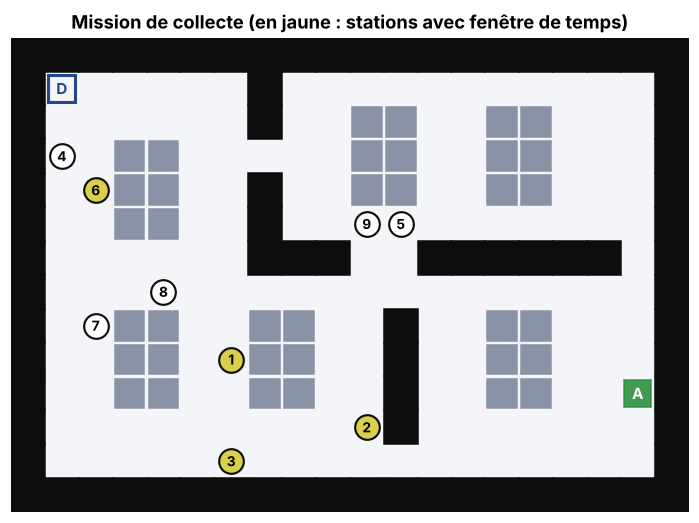

In [4]:
def dessiner_tournee(probleme, ordre=None, ax=None, titre=None, nom="tournée"):
    """Dessine les stations sur le plan de l'entrepôt et, si un ordre est donné, la tournée complète."""
    trajectoires = {nom: [tuple(c) for c in chemin_complet(probleme, ordre)]} if ordre else None
    ax = dessiner_monde(probleme.monde, ax, trajectoires=trajectoires, titre=titre)
    rang = {s: k + 1 for k, s in enumerate(ordre)} if ordre else {}
    for s, (x, y) in enumerate(probleme.stations, start=1):
        couleur = JAUNE if s in probleme.fenetres else "white"
        ax.scatter([x + 0.5], [y + 0.5], s=260, color=couleur, edgecolor=NOIR, lw=1.4, zorder=8)
        ax.text(x + 0.5, y + 0.5, str(s), ha="center", va="center", fontsize=9, weight="bold", zorder=9)
        if s in rang:
            ax.text(x + 0.95, y + 0.1, f"{rang[s]}e", fontsize=7, color=ROUGE, zorder=9)
    return ax


dessiner_tournee(probleme, titre="Mission de collecte (en jaune : stations avec fenêtre de temps)")
plt.show()

### Taille de l'espace de recherche

Avec n stations, il existe n! ordres possibles. L'énumération complète devient vite hors de portée.

In [5]:
for n in (5, 9, 12, 15, 20):
    print(f"n = {n:2d} : {math.factorial(n):>22,d} ordres possibles".replace(",", " "))

# Évaluation de deux candidats simples : un ordre au hasard et l'heuristique du plus proche voisin.
rng = np.random.default_rng(0)
hasard = [int(s) for s in rng.permutation(np.arange(1, probleme.n + 1))]
glouton = plus_proche_voisin(probleme)
for nom, ordre in (("Ordre au hasard", hasard), ("Plus proche voisin", glouton)):
    ev = probleme.evaluer(ordre)
    print(f"{nom:20s} {ordre} : coût {ev['cout']}, contraintes non respectées {ev['non_respectees']}, retard {ev['retard']}")

n =  5 :                    120 ordres possibles
n =  9 :                362 880 ordres possibles
n = 12 :            479 001 600 ordres possibles
n = 15 :      1 307 674 368 000 ordres possibles
n = 20 : 2 432 902 008 176 640 000 ordres possibles
Ordre au hasard      [5, 6, 3, 7, 4, 9, 8, 1, 2] : coût 104, contraintes non respectées 5, retard 142
Plus proche voisin   [4, 6, 7, 8, 1, 3, 2, 9, 5] : coût 44, contraintes non respectées 2, retard 10


Le plus proche voisin donne une tournée courte, mais il ignore les contraintes : sa solution n'est en général pas réalisable. Il faut une méthode qui tienne compte des contraintes pendant la recherche.

## Partie 2. Programmation sous contraintes à la main

La programmation sous contraintes repose sur trois idées :

1. **Variables et domaines.** Ici, la variable de rang k désigne la station visitée en k-ième position. Son domaine est l'ensemble des stations pas encore visitées.
2. **Propagation.** Après chaque choix, on retire des domaines les valeurs devenues impossibles. Si une station ne peut plus être atteinte avant la fermeture de sa fenêtre, la branche entière est abandonnée sans être explorée.
3. **Retour arrière.** Quand une branche échoue, on revient au dernier choix et on essaie la valeur suivante.

On y ajoute une **borne** : si le coût déjà engagé, augmenté d'une estimation optimiste du reste, dépasse la meilleure solution connue, la branche est coupée.

In [6]:
def retour_arriere(probleme, propagation=True, borne=True):
    """Recherche exacte par retour arrière. Retourne (meilleur ordre, meilleur coût, noeuds explorés)."""
    d, n, service = probleme.distances, probleme.n, probleme.service
    avant = {j: {i for i, jj in probleme.precedences if jj == j} for j in range(1, n + 1)}
    # Estimation optimiste : chaque point restant coûte au moins son arc entrant le moins cher.
    arc_min = [min(d[i, j] for i in range(n + 1) if i != j) for j in range(n + 1)]
    etat = {"meilleur": None, "cout": float("inf"), "noeuds": 0}

    def explorer(ordre, courant, t, cout, restantes):
        etat["noeuds"] += 1
        if not restantes:
            total = cout + d[courant, 0]
            if total < etat["cout"]:
                etat["meilleur"], etat["cout"] = list(ordre), int(total)
            return
        if borne and cout + sum(arc_min[s] for s in restantes) + arc_min[0] >= etat["cout"]:
            return  # coupe : cette branche ne peut pas battre la meilleure solution connue
        if propagation:
            # Chaque station restante avec fenêtre doit rester atteignable à temps, au mieux en ligne directe.
            for s in restantes:
                if s in probleme.fenetres and t + d[courant, s] > probleme.fenetres[s][1]:
                    return
        for s in sorted(restantes, key=lambda s: d[courant, s]):
            if avant[s] & restantes:
                continue  # précédence : une station requise avant s n'est pas encore visitée
            arrivee = t + d[courant, s]
            if s in probleme.fenetres:
                arrivee = max(arrivee, probleme.fenetres[s][0])
                if arrivee > probleme.fenetres[s][1]:
                    continue  # fenêtre manquée
            explorer(ordre + [s], s, arrivee + service, cout + d[courant, s], restantes - {s})

    explorer([], 0, 0, 0, frozenset(range(1, n + 1)))
    return etat["meilleur"], etat["cout"], etat["noeuds"]


# Petit cas : 8 stations, 2 fenêtres de temps, 2 précédences.
PETIT = {"n_stations": 8, "graine": 4130, "n_fenetres": 2, "n_precedences": 2}
petit = creer_probleme(**PETIT)
print("Fenêtres :", petit.fenetres, " Précédences :", petit.precedences)
lignes = []
for propagation, borne in itertools.product([False, True], repeat=2):
    debut = time.perf_counter()
    ordre, cout, noeuds = retour_arriere(petit, propagation, borne)
    lignes.append({"propagation": propagation, "borne": borne, "coût": cout, "noeuds explorés": noeuds,
                   "durée (ms)": round((time.perf_counter() - debut) * 1000, 1)})
print(f"Énumération complète sans contraintes : {math.factorial(petit.n)} ordres")
pd.DataFrame(lignes)

Fenêtres : {8: (33, 41), 6: (21, 29)}  Précédences : [(7, 6), (5, 4)]
Énumération complète sans contraintes : 40320 ordres


,propagation,borne,coût,noeuds explorés,durée (ms)
0,False,False,54,6273,8.0
1,False,True,54,3052,4.7
2,True,False,54,1151,1.1
3,True,True,54,733,1.1


Les quatre variantes trouvent le même coût optimal, mais le nombre de noeuds explorés change beaucoup. Les contraintes ne sont pas un obstacle pour ce type de méthode : elles **réduisent** l'espace à explorer.

### Exercice 1. Mesurer l'effet d'une contrainte supplémentaire

Ajoutez une précédence au petit problème (par exemple la station 3 avant la station 8), puis relancez la recherche. Observez le coût optimal et le nombre de noeuds explorés. Que se passe-t-il si vous ajoutez une précédence contradictoire avec une précédence existante ?

In [7]:
# À VOUS : modifiez la liste des précédences ajoutées, puis exécutez la cellule.
PRECEDENCES_AJOUTEES = [(3, 8)]

essai = creer_probleme(**PETIT)
essai.precedences = essai.precedences + PRECEDENCES_AJOUTEES
ordre, cout, noeuds = retour_arriere(essai)
print("Précédences :", essai.precedences)
print(f"Meilleur ordre : {ordre}, coût : {cout}, noeuds explorés : {noeuds}")

Précédences : [(7, 6), (5, 4), (3, 8)]
Meilleur ordre : [1, 2, 7, 5, 6, 3, 8, 4], coût : 56, noeuds explorés : 344


**Solution possible.** On compare trois situations : le problème d'origine, une précédence compatible et une précédence contradictoire (le couple inverse d'une précédence existante).

In [8]:
i, j = petit.precedences[0]
for nom, ajout in (("origine", []), ("compatible", [(5, 7)]), ("contradictoire", [(j, i)])):
    essai = creer_probleme(**PETIT)
    essai.precedences = essai.precedences + ajout
    ordre, cout, noeuds = retour_arriere(essai)
    print(f"{nom:15s} ordre {ordre}, coût {cout}, noeuds {noeuds}")
print("Une contrainte compatible augmente le coût optimal mais réduit le nombre de noeuds explorés.")
print("Avec des contraintes contradictoires, la recherche prouve qu'aucune solution n'existe (ordre None), et elle le prouve très vite.")

origine         ordre [1, 2, 7, 5, 6, 8, 3, 4], coût 54, noeuds 733
compatible      ordre [1, 2, 5, 7, 6, 8, 3, 4], coût 58, noeuds 197
contradictoire  ordre None, coût inf, noeuds 54
Une contrainte compatible augmente le coût optimal mais réduit le nombre de noeuds explorés.
Avec des contraintes contradictoires, la recherche prouve qu'aucune solution n'existe (ordre None), et elle le prouve très vite.


## Partie 3. CP-SAT, un solveur de programmation sous contraintes

En pratique, on décrit le modèle et on confie la recherche à un solveur. CP-SAT (OR-Tools) combine propagation, apprentissage de conflits et bornes. Le modèle ci-dessous est écrit en entier pour être lisible :

- un booléen par arc (i vers j), vrai si le robot va directement de i à j ;
- une contrainte de **circuit** : les arcs choisis forment une seule boucle qui passe partout ;
- une variable de temps par station, bornée par sa fenêtre ;
- si l'arc (i vers j) est choisi, alors temps[j] ≥ temps[i] + service + distance(i, j) ;
- chaque précédence est une inégalité entre deux variables de temps.

**Note sur le matériel.** CP-SAT s'exécute sur CPU, en parallèle sur plusieurs coeurs. Un GPU ne l'accélère pas : la recherche arborescente n'est pas un calcul tensoriel.

CP-SAT : ordre [4, 6, 7, 2, 1, 3, 9, 5, 8], coût 58, statut OPTIMAL, durée 33 ms
Vérification indépendante : {'cout': 58, 'retard': 0, 'non_respectees': 0, 'faisable': True, 'duree_totale': 76}


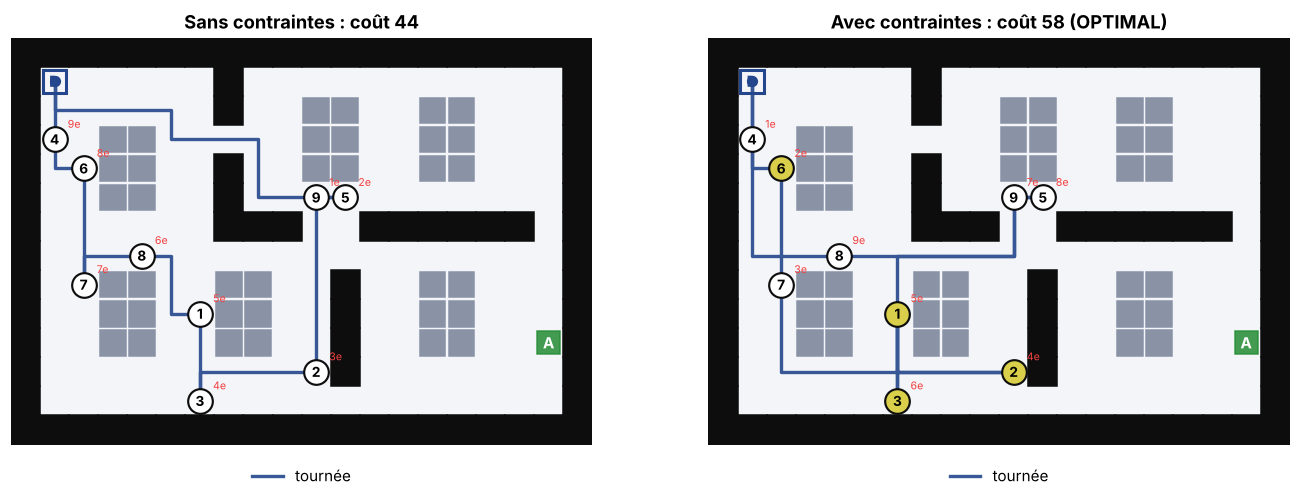

In [9]:
from ortools.sat.python import cp_model


def modele_cp_sat(probleme, limite_s=10.0):
    n, d, service = probleme.n, probleme.distances, probleme.service
    horizon = int(d.max()) * (n + 1) + service * n + 100
    modele = cp_model.CpModel()
    arc = {(i, j): modele.NewBoolVar(f"arc_{i}_{j}") for i in range(n + 1) for j in range(n + 1) if i != j}
    modele.AddCircuit([(i, j, v) for (i, j), v in arc.items()])
    temps = {0: modele.NewConstant(0)}
    for s in range(1, n + 1):
        bas, haut = probleme.fenetres.get(s, (0, horizon))
        temps[s] = modele.NewIntVar(bas, haut, f"t_{s}")  # la fenêtre est le domaine de la variable
    for (i, j), v in arc.items():
        if j != 0:
            modele.Add(temps[j] >= temps[i] + (service if i else 0) + int(d[i, j])).OnlyEnforceIf(v)
    for i, j in probleme.precedences:
        modele.Add(temps[j] >= temps[i] + service + int(d[i, j]))
    modele.Minimize(sum(int(d[i, j]) * v for (i, j), v in arc.items()))
    solveur = cp_model.CpSolver()
    solveur.parameters.max_time_in_seconds = limite_s
    statut = solveur.Solve(modele)
    ordre, courant = [], 0
    for _ in range(n):
        courant = next(j for j in range(n + 1) if j != courant and solveur.BooleanValue(arc[courant, j]))
        ordre.append(courant)
    return ordre, int(solveur.ObjectiveValue()), solveur.StatusName(statut), solveur.WallTime()


ordre_cp, cout_cp, statut, duree = modele_cp_sat(probleme)
print(f"CP-SAT : ordre {ordre_cp}, coût {cout_cp}, statut {statut}, durée {duree * 1000:.0f} ms")
print("Vérification indépendante :", {k: v for k, v in probleme.evaluer(ordre_cp).items() if k != "debuts"})

libre = resoudre_cp_sat(probleme.sans_contraintes())
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
dessiner_tournee(probleme.sans_contraintes(), libre["ordre"], axes[0], f"Sans contraintes : coût {libre['cout']}")
dessiner_tournee(probleme, ordre_cp, axes[1], f"Avec contraintes : coût {cout_cp} ({statut})")
plt.show()

Le statut `OPTIMAL` est une **preuve** : aucune tournée réalisable n'est plus courte. C'est la différence de nature avec une métaheuristique, qui fournit une bonne solution sans garantie. Respecter les contraintes a un prix, visible dans l'écart de coût entre les deux tournées.

### Exercice 2. Resserrer une fenêtre de temps

Choisissez une station avec fenêtre et réduisez sa fermeture de quelques pas. Relancez le solveur (la fonction `resoudre_cp_sat` du paquet est équivalente au modèle ci-dessus). À partir de quelle valeur le problème devient-il irréalisable ?

In [10]:
# À VOUS : choisissez la station et la réduction de la fermeture.
STATION = sorted(probleme.fenetres)[0]
REDUCTION = 2

essai = creer_probleme(**PARAMETRES_PROBLEME)
ouverture, fermeture = essai.fenetres[STATION]
essai.fenetres[STATION] = (ouverture, max(ouverture, fermeture - REDUCTION))
r = resoudre_cp_sat(essai)
print(f"Station {STATION} : fenêtre {essai.fenetres[STATION]}, statut {r['statut']}, coût {r['cout']}, ordre {r['ordre']}")

Station 1 : fenêtre (29, 35), statut OPTIMAL, coût 58, ordre [4, 6, 7, 2, 1, 3, 5, 9, 8]


**Solution possible.** On balaie la réduction pour chaque station avec fenêtre et on note le coût optimal obtenu.

In [11]:
lignes = []
for station in sorted(probleme.fenetres):
    for reduction in range(0, PARAMETRES_PROBLEME["marge"] + 1, 2):
        essai = creer_probleme(**PARAMETRES_PROBLEME)
        o, f = essai.fenetres[station]
        essai.fenetres[station] = (o, max(o, f - reduction))
        r = resoudre_cp_sat(essai)
        lignes.append({"station": f"S{station}", "réduction": reduction, "coût": r["cout"] if r["cout"] is not None else np.nan})
tableau = pd.DataFrame(lignes).pivot(index="station", columns="réduction", values="coût")
print("Coût optimal selon la réduction de la fermeture (NaN : problème irréalisable)")
tableau

Coût optimal selon la réduction de la fermeture (NaN : problème irréalisable)


réduction,0,2,4,6,8
station,,,,,
S1,58.0,58.0,58.0,NaN,NaN
S2,58.0,58.0,58.0,58.0,58.0
S3,58.0,58.0,58.0,58.0,NaN
S6,58.0,58.0,58.0,58.0,62.0


## Partie 4. Recuit simulé

Le recuit simulé est une recherche locale qui accepte parfois de dégrader la solution courante, pour sortir des minima locaux. À chaque itération :

1. tirer un **voisin** de la solution courante (ici : échanger deux stations, déplacer une station ou inverser un segment) ;
2. calculer Δ = énergie(voisin) - énergie(courante) ;
3. accepter le voisin si Δ ≤ 0, sinon l'accepter avec la probabilité exp(-Δ / T) (critère de Metropolis) ;
4. **refroidir** : T devient α × T.

À haute température, presque tout est accepté (exploration). À basse température, seules les améliorations passent (exploitation).

Les contraintes entrent dans l'**énergie** sous forme de pénalités : énergie = coût + poids × (contraintes non respectées) + retard. Le recuit peut donc traverser des solutions non réalisables.

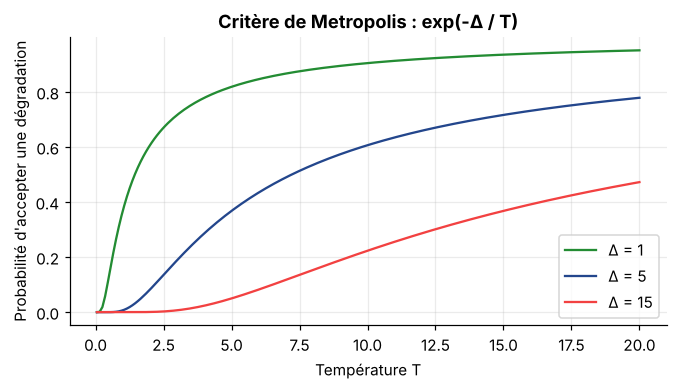

In [12]:
T = np.linspace(0.05, 20, 200)
fig, ax = plt.subplots(figsize=(7, 3.4))
for delta, couleur in ((1, VERT), (5, BLEU), (15, ROUGE)):
    ax.plot(T, np.exp(-delta / T), color=couleur, label=f"Δ = {delta}")
ax.set_xlabel("Température T")
ax.set_ylabel("Probabilité d'accepter une dégradation")
ax.set_title("Critère de Metropolis : exp(-Δ / T)")
ax.legend()
plt.show()

In [13]:
def voisin(ordre, rng):
    """Tire un voisin de l'ordre courant."""
    i, j = sorted(int(k) for k in rng.choice(len(ordre), size=2, replace=False))
    nouveau = list(ordre)
    tirage = rng.random()
    if tirage < 1 / 3:    # échange de deux stations
        nouveau[i], nouveau[j] = nouveau[j], nouveau[i]
    elif tirage < 2 / 3:  # déplacement d'une station
        nouveau.insert(j, nouveau.pop(i))
    else:                 # inversion d'un segment
        nouveau[i:j + 1] = reversed(nouveau[i:j + 1])
    return nouveau


def mon_recuit(probleme, T0, alpha, iterations, graine, poids_penalite=30.0):
    """Recuit simulé. Retourne (meilleur ordre, historique)."""
    rng = np.random.default_rng(graine)
    courant = [int(s) for s in rng.permutation(np.arange(1, probleme.n + 1))]
    e_courant = probleme.energie(courant, poids_penalite)
    meilleur, e_meilleur = list(courant), e_courant
    T, historique = T0, []
    for it in range(iterations):
        candidat = voisin(courant, rng)
        e_candidat = probleme.energie(candidat, poids_penalite)
        delta = e_candidat - e_courant
        accepte = delta <= 0 or rng.random() < math.exp(-delta / T)  # critère de Metropolis
        if accepte:
            courant, e_courant = candidat, e_candidat
            if e_courant < e_meilleur:
                meilleur, e_meilleur = list(courant), e_courant
        historique.append({"it": it, "temperature": T, "courant": e_courant, "meilleur": e_meilleur, "accepte": accepte, "delta": delta})
        T *= alpha  # refroidissement géométrique
    return meilleur, pd.DataFrame(historique)

Recuit : ordre [6, 2, 1, 3, 9, 5, 8, 4, 7], coût 70, contraintes non respectées 0
CP-SAT : coût optimal 58. Écart du recuit : 20.7 %


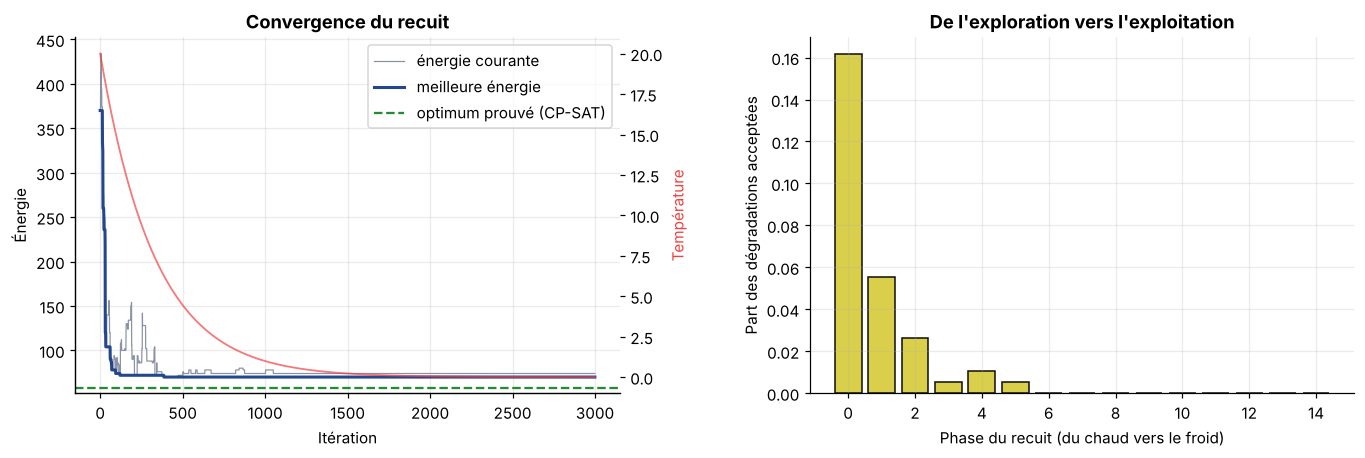

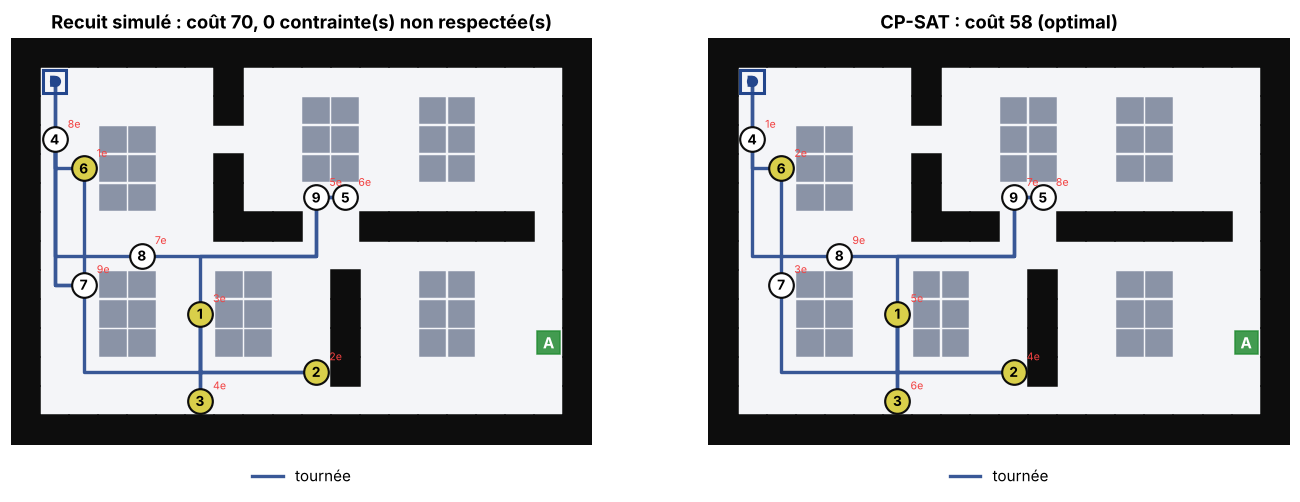

In [14]:
# PARAMÈTRES MODIFIABLES : réglage du recuit simulé.
PARAMETRES_RECUIT = {
    "T0": 20.0,          # température initiale
    "alpha": 0.997,      # facteur de refroidissement (proche de 1 : refroidissement lent)
    "iterations": 3000,  # nombre d'itérations
    "graine": 4130,      # graine aléatoire
    "poids_penalite": 30.0,  # coût d'une contrainte non respectée
}
ordre_rs, historique = mon_recuit(probleme, **PARAMETRES_RECUIT)
ev = probleme.evaluer(ordre_rs)
print(f"Recuit : ordre {ordre_rs}, coût {ev['cout']}, contraintes non respectées {ev['non_respectees']}")
print(f"CP-SAT : coût optimal {cout_cp}. Écart du recuit : {100 * (ev['cout'] - cout_cp) / cout_cp:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]
ax.plot(historique["it"], historique["courant"], color=GRIS, lw=0.8, label="énergie courante")
ax.plot(historique["it"], historique["meilleur"], color=BLEU, lw=2, label="meilleure énergie")
ax.axhline(cout_cp, color=VERT, ls="--", label="optimum prouvé (CP-SAT)")
ax.set_xlabel("Itération")
ax.set_ylabel("Énergie")
ax.set_title("Convergence du recuit")
ax2 = ax.twinx()
ax2.plot(historique["it"], historique["temperature"], color=ROUGE, lw=1.2, alpha=0.7)
ax2.set_ylabel("Température", color=ROUGE)
ax2.grid(False)
ax.legend(loc="upper right")
taux = historique.assign(degradation=historique["delta"] > 0)
taux = taux[taux["degradation"]].groupby(taux["it"] // (PARAMETRES_RECUIT["iterations"] // 15))["accepte"].mean()
axes[1].bar(taux.index, taux.values, color=JAUNE, edgecolor=NOIR)
axes[1].set_xlabel("Phase du recuit (du chaud vers le froid)")
axes[1].set_ylabel("Part des dégradations acceptées")
axes[1].set_title("De l'exploration vers l'exploitation")
fig.subplots_adjust(wspace=0.35)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
dessiner_tournee(probleme, ordre_rs, axes[0], f"Recuit simulé : coût {ev['cout']}, {ev['non_respectees']} contrainte(s) non respectée(s)")
dessiner_tournee(probleme, ordre_cp, axes[1], f"CP-SAT : coût {cout_cp} (optimal)")
plt.show()

La fonction `recuit_simule` du paquet fait le même calcul et conserve en plus des instantanés de la tournée, utilisés par l'animation du site. Vérifions que les deux versions se comportent de la même manière.

In [15]:
ref = recuit_simule(probleme, **PARAMETRES_RECUIT)
print(f"Paquet : coût {ref['cout']}, contraintes non respectées {ref['non_respectees']}, durée {ref['duree_s'] * 1000:.0f} ms pour {ref['iterations']} itérations")
print("Instantanés :", [(p["it"], p["cout"], p["non_respectees"]) for p in ref["instantanes"][:6]], "...")

Paquet : coût 70, contraintes non respectées 0, durée 108 ms pour 3000 itérations
Instantanés : [(0, 96, 4), (272, 76, 1), (544, 78, 0), (816, 74, 0), (1088, 74, 0), (1360, 74, 0)] ...


### Exercice 3. Régler la température et le refroidissement

Un recuit dépend d'un tirage aléatoire : pour juger un réglage, il faut le répéter sur plusieurs graines. Complétez la grille ci-dessous avec vos valeurs de T₀ et de α, puis identifiez les réglages qui atteignent le plus souvent l'optimum. Que se passe-t-il quand T₀ est très bas ? Quand α est trop petit ?

In [16]:
# À VOUS : choisissez les valeurs à tester.
GRILLE_T0 = [0.5, 20.0]
GRILLE_ALPHA = [0.95, 0.997]
GRAINES = range(5)


def etudier(grille_T0, grille_alpha, graines, iterations=3000):
    ecarts = np.zeros((len(grille_T0), len(grille_alpha)))
    for a, T0 in enumerate(grille_T0):
        for b, alpha in enumerate(grille_alpha):
            energies = [recuit_simule(probleme, T0=T0, alpha=alpha, iterations=iterations, graine=g)["energie"] for g in graines]
            ecarts[a, b] = 100 * (np.mean(energies) - cout_cp) / cout_cp
    return pd.DataFrame(ecarts, index=[f"T₀ = {v}" for v in grille_T0], columns=[f"α = {v}" for v in grille_alpha]).round(1)


print("Écart moyen à l'optimum, en % (0 : optimum atteint à chaque essai)")
etudier(GRILLE_T0, GRILLE_ALPHA, GRAINES)

Écart moyen à l'optimum, en % (0 : optimum atteint à chaque essai)


,α = 0.95,α = 0.997
T₀ = 0.5,15.9,15.9
T₀ = 20.0,24.1,13.1


**Solution possible.** Une grille plus fine, affichée sous forme de carte de chaleur.

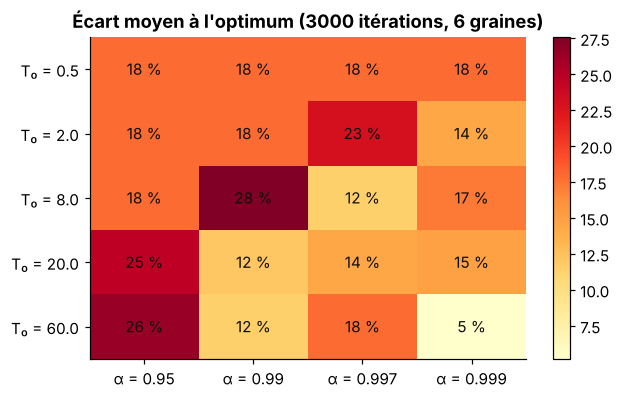

Lecture : un T₀ très bas transforme le recuit en simple descente, bloquée dans un minimum local.
Un α trop petit refroidit trop vite : la phase d'exploration est trop courte.
Un T₀ très haut avec un α très proche de 1 reste chaud trop longtemps pour le budget d'itérations.


In [17]:
grille_T0 = [0.5, 2.0, 8.0, 20.0, 60.0]
grille_alpha = [0.95, 0.99, 0.997, 0.999]
ecarts = etudier(grille_T0, grille_alpha, range(6))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
image = ax.imshow(ecarts.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(grille_alpha)), ecarts.columns)
ax.set_yticks(range(len(grille_T0)), ecarts.index)
for (a, b), v in np.ndenumerate(ecarts.values):
    ax.text(b, a, f"{v:.0f} %", ha="center", va="center", color=NOIR)
ax.grid(False)
ax.set_title("Écart moyen à l'optimum (3000 itérations, 6 graines)")
plt.colorbar(image, ax=ax)
plt.show()
print("Lecture : un T₀ très bas transforme le recuit en simple descente, bloquée dans un minimum local.")
print("Un α trop petit refroidit trop vite : la phase d'exploration est trop courte.")
print("Un T₀ très haut avec un α très proche de 1 reste chaud trop longtemps pour le budget d'itérations.")

### Exercice 4. Le poids des pénalités

Le poids de pénalité fixe le prix d'une contrainte non respectée. Testez plusieurs valeurs et observez la part des essais qui se terminent sur une solution réalisable.

In [18]:
# À VOUS : choisissez les poids à comparer.
POIDS = [0.0, 30.0]

for poids in POIDS:
    essais = [recuit_simule(probleme, iterations=3000, alpha=0.997, graine=g, poids_penalite=poids) for g in range(8)]
    realisables = np.mean([e["faisable"] for e in essais])
    print(f"poids {poids:6.1f} : {100 * realisables:3.0f} % d'essais réalisables, coût moyen {np.mean([e['cout'] for e in essais]):.1f}")

poids    0.0 :   0 % d'essais réalisables, coût moyen 49.0
poids   30.0 : 100 % d'essais réalisables, coût moyen 66.2


**Solution possible.**

In [19]:
lignes = []
for poids in [0.0, 2.0, 10.0, 30.0, 100.0, 1000.0]:
    essais = [recuit_simule(probleme, iterations=3000, alpha=0.997, graine=g, poids_penalite=poids) for g in range(8)]
    lignes.append({"poids": poids, "essais réalisables (%)": 100 * np.mean([e["faisable"] for e in essais]),
                   "coût moyen": np.mean([e["cout"] for e in essais]),
                   "optimum atteint (%)": 100 * np.mean([e["faisable"] and e["cout"] == cout_cp for e in essais])})
print("Un poids nul ignore les contraintes : tournée courte mais non réalisable.")
print("Un poids très élevé dresse des murs dans le paysage d'énergie : le recuit a du mal à traverser les zones non réalisables.")
pd.DataFrame(lignes).round(1)

Un poids nul ignore les contraintes : tournée courte mais non réalisable.
Un poids très élevé dresse des murs dans le paysage d'énergie : le recuit a du mal à traverser les zones non réalisables.


,poids,essais réalisables (%),coût moyen,optimum atteint (%)
0,0.0,0.0,49.0,0.0
1,2.0,25.0,51.0,25.0
2,10.0,62.5,59.8,12.5
3,30.0,100.0,66.2,0.0
4,100.0,100.0,65.2,12.5
5,1000.0,100.0,63.0,12.5


## Partie 5. Comparaison selon la taille du problème

Les deux approches n'ont pas le même profil. On mesure, pour un nombre croissant de stations : le coût et la durée de CP-SAT (avec une limite de temps), le coût médian et la durée du recuit.

In [20]:
# PARAMÈTRES MODIFIABLES : campagne de comparaison.
PARAMETRES_COMPARAISON = {
    "tailles": [6, 8, 10, 12, 14, 18, 22],
    "limite_cp_sat_s": 4.0,
    "iterations_recuit": 10000,
    "alpha": 0.9995,
    "graines_recuit": 5,
}
lignes = []
for n in PARAMETRES_COMPARAISON["tailles"]:
    p = creer_probleme(n_stations=n, graine=4130)
    cp = resoudre_cp_sat(p, limite_s=PARAMETRES_COMPARAISON["limite_cp_sat_s"])
    essais = [recuit_simule(p, iterations=PARAMETRES_COMPARAISON["iterations_recuit"], alpha=PARAMETRES_COMPARAISON["alpha"], graine=g)
              for g in range(PARAMETRES_COMPARAISON["graines_recuit"])]
    realisables = [e["cout"] for e in essais if e["faisable"]]
    lignes.append({
        "n": n, "CP-SAT coût": cp["cout"], "CP-SAT statut": cp["statut"], "CP-SAT durée (s)": cp["duree_s"],
        "recuit coût médian": np.median(realisables) if realisables else np.nan,
        "recuit réalisables": f"{len(realisables)}/{len(essais)}",
        "recuit durée (s)": round(np.mean([e["duree_s"] for e in essais]), 3),
    })
comparaison = pd.DataFrame(lignes)
comparaison["écart recuit (%)"] = (100 * (comparaison["recuit coût médian"] - comparaison["CP-SAT coût"]) / comparaison["CP-SAT coût"]).round(1)
comparaison

,n,CP-SAT coût,CP-SAT statut,CP-SAT durée (s),recuit coût médian,recuit réalisables,recuit durée (s),écart recuit (%)
0,6,52,OPTIMAL,0.0050,52.0,5/5,0.117,0.0
1,8,54,OPTIMAL,0.0072,54.0,5/5,0.156,0.0
2,10,58,OPTIMAL,0.0146,76.0,2/5,0.115,31.0
3,12,72,OPTIMAL,0.0339,76.0,5/5,0.150,5.6
4,14,76,OPTIMAL,0.0418,98.0,5/5,0.133,28.9
5,18,82,OPTIMAL,0.1067,86.0,5/5,0.146,4.9
6,22,86,OPTIMAL,0.5008,124.0,5/5,0.164,44.2


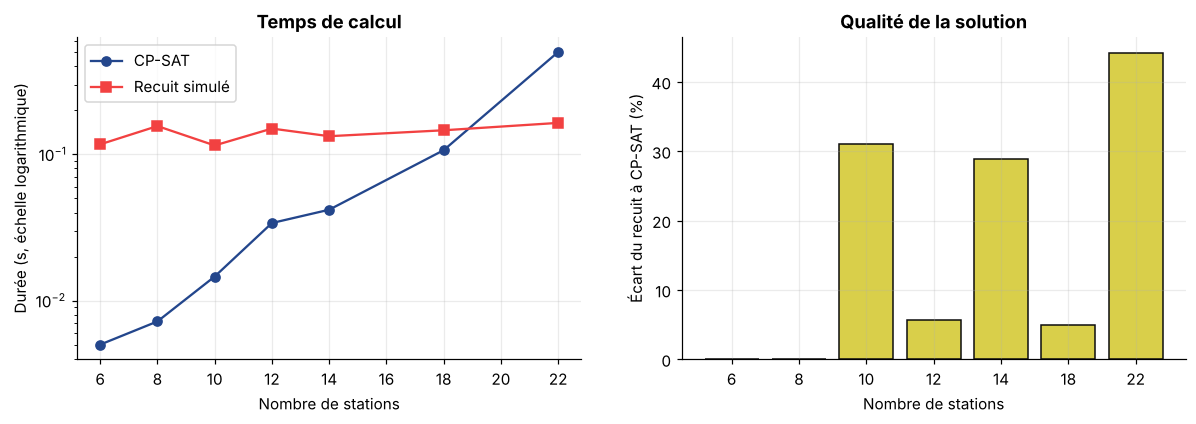

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(comparaison["n"], comparaison["CP-SAT durée (s)"], "o-", color=BLEU, label="CP-SAT")
axes[0].plot(comparaison["n"], comparaison["recuit durée (s)"], "s-", color=ROUGE, label="Recuit simulé")
axes[0].set_yscale("log")
axes[0].set_xlabel("Nombre de stations")
axes[0].set_ylabel("Durée (s, échelle logarithmique)")
axes[0].set_title("Temps de calcul")
axes[0].legend()
axes[1].bar(comparaison["n"].astype(str), comparaison["écart recuit (%)"].fillna(0), color=JAUNE, edgecolor=NOIR)
axes[1].set_xlabel("Nombre de stations")
axes[1].set_ylabel("Écart du recuit à CP-SAT (%)")
axes[1].set_title("Qualité de la solution")
plt.show()

**Lecture des résultats.**

- Sur ces tailles, CP-SAT trouve l'optimum et le prouve en moins d'une seconde. Le recuit n'a pas d'avantage, et les fenêtres de temps lui compliquent la tâche : son écart à l'optimum varie beaucoup d'une instance à l'autre.
- La durée de CP-SAT croît vite avec la taille. Sur des instances plus grandes ou plus contraintes, elle finit par toucher la limite de temps : le statut passe alors de `OPTIMAL` à `FAISABLE` (bonne solution, sans preuve). Essayez avec 26 ou 30 stations.
- La durée du recuit ne dépend presque pas de la taille : elle est fixée par le budget d'itérations. Sa qualité, en revanche, se dégrade si le budget n'augmente pas.

Le choix dépend donc des contraintes de performance : besoin d'une preuve ou d'une garantie de respect des contraintes (programmation sous contraintes), ou besoin d'une réponse en temps borné sur un grand problème, avec une fonction de coût quelconque (recuit simulé).

## Partie 6. Recuit par lots : des milliers de chaînes en parallèle

Un recuit isolé est séquentiel : chaque itération dépend de la précédente, un GPU ne l'accélère pas. En revanche, on peut lancer des milliers de recuits **indépendants** en même temps et garder le meilleur. L'évaluation de milliers de tournées à la fois est un calcul tensoriel, et c'est là que le GPU est utile. La fonction `recuit_lot` représente les tournées par un tenseur (chaînes × stations).

Optimum CP-SAT (OPTIMAL) : 76
Une chaîne séquentielle (Python)   : coût 122  72 289 évaluations par seconde
1024 chaînes sur cpu               : coût 76  779 200 évaluations par seconde  durée 0.79 s
Pas de GPU détecté : la comparaison CPU / GPU est ignorée, le reste du notebook est inchangé.


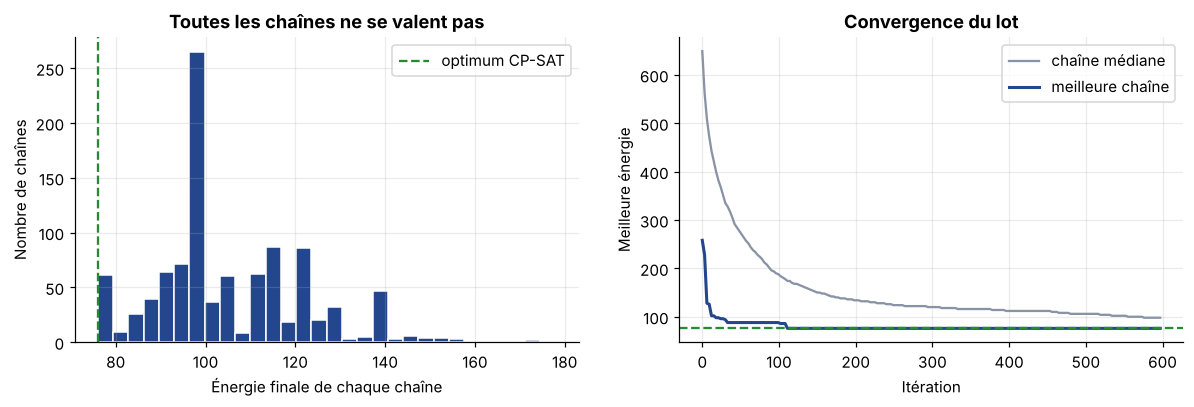

In [22]:
# PARAMÈTRES MODIFIABLES : recuit par lots.
PARAMETRES_LOT = {"chaines": 1024, "iterations": 600, "T0": 20.0, "alpha": 0.992}
grand = creer_probleme(n_stations=14, graine=4130)
optimum = resoudre_cp_sat(grand, limite_s=10)

lot = recuit_lot(grand, appareil=APPAREIL, **PARAMETRES_LOT)
sequentiel = recuit_simule(grand, iterations=PARAMETRES_LOT["iterations"], T0=PARAMETRES_LOT["T0"], alpha=PARAMETRES_LOT["alpha"])
debit_seq = sequentiel["iterations"] / sequentiel["duree_s"]
print(f"Optimum CP-SAT ({optimum['statut']}) : {optimum['cout']}")
print(f"Une chaîne séquentielle (Python)   : coût {sequentiel['cout']}, {debit_seq:,.0f} évaluations par seconde".replace(",", " "))
print(f"{lot['chaines']} chaînes sur {lot['appareil']:4s}              : coût {lot['cout']}, {lot['evaluations_par_seconde']:,d} évaluations par seconde, durée {lot['duree_s']:.2f} s".replace(",", " "))
if str(APPAREIL) != "cpu":
    cpu = recuit_lot(grand, appareil="cpu", **PARAMETRES_LOT)
    print(f"Même lot sur CPU                    : {cpu['evaluations_par_seconde']:,d} évaluations par seconde, soit un facteur {lot['evaluations_par_seconde'] / cpu['evaluations_par_seconde']:.1f} en faveur du GPU".replace(",", " "))
else:
    print("Pas de GPU détecté : la comparaison CPU / GPU est ignorée, le reste du notebook est inchangé.")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(lot["energies_finales"], bins=30, color=BLEU, edgecolor="white")
axes[0].axvline(optimum["cout"], color=VERT, ls="--", label="optimum CP-SAT")
axes[0].set_xlabel("Énergie finale de chaque chaîne")
axes[0].set_ylabel("Nombre de chaînes")
axes[0].set_title("Toutes les chaînes ne se valent pas")
axes[0].legend()
courbe = pd.DataFrame(lot["courbe"])
axes[1].plot(courbe["it"], courbe["mediane"], color=GRIS, label="chaîne médiane")
axes[1].plot(courbe["it"], courbe["meilleur"], color=BLEU, lw=2, label="meilleure chaîne")
axes[1].axhline(optimum["cout"], color=VERT, ls="--")
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("Meilleure énergie")
axes[1].set_title("Convergence du lot")
axes[1].legend()
plt.show()

### Exercice 5. Combien de chaînes faut-il ?

À budget d'itérations fixé, faites varier le nombre de chaînes et observez le coût de la meilleure chaîne et le débit. Le débit par chaîne reste-t-il constant ?

In [23]:
# À VOUS : choisissez les tailles de lot à comparer.
TAILLES_LOT = [16, 1024]

for chaines in TAILLES_LOT:
    r = recuit_lot(grand, chaines=chaines, iterations=600, alpha=0.992, appareil=APPAREIL)
    print(f"{chaines:5d} chaînes : coût {r['cout']}, réalisable {r['faisable']}, {r['evaluations_par_seconde']:>10,d} évaluations par seconde".replace(",", " "))

   16 chaînes : coût 78  réalisable True      37 016 évaluations par seconde


 1024 chaînes : coût 76  réalisable True     904 333 évaluations par seconde


**Solution possible.**

In [24]:
lignes = []
for chaines in [1, 16, 128, 1024, 2048]:
    r = recuit_lot(grand, chaines=chaines, iterations=600, alpha=0.992, appareil=APPAREIL)
    lignes.append({"chaînes": chaines, "coût": r["cout"], "réalisable": r["faisable"], "écart à l'optimum (%)": round(100 * (r["cout"] - optimum["cout"]) / optimum["cout"], 1),
                   "durée (s)": r["duree_s"], "évaluations par seconde": r["evaluations_par_seconde"]})
print("Le coût fixe par itération (interprète Python, lancement des opérations) est partagé entre les chaînes :")
print("le débit augmente fortement avec la taille du lot, jusqu'à saturation de la mémoire ou du processeur.")
pd.DataFrame(lignes)

Le coût fixe par itération (interprète Python, lancement des opérations) est partagé entre les chaînes :
le débit augmente fortement avec la taille du lot, jusqu'à saturation de la mémoire ou du processeur.


,chaînes,coût,réalisable,écart à l'optimum (%),durée (s),évaluations par seconde
0,1,98,True,28.9,0.2615,2295
1,16,78,True,2.6,0.2339,41047
2,128,76,True,0.0,0.2797,274546
3,1024,76,True,0.0,0.6762,908639
4,2048,76,True,0.0,1.0876,1129786


## Synthèse du module

- Un problème d'optimisation pour un agent se définit par des variables de décision, une fonction de coût et des contraintes. L'espace de recherche d'une tournée de n stations compte n! ordres.
- La programmation sous contraintes exploite les contraintes pour élaguer la recherche (propagation, retour arrière, bornes). Un solveur comme CP-SAT fournit une solution et la preuve de son optimalité, sur CPU.
- Le recuit simulé explore par voisinage et accepte des dégradations avec la probabilité exp(-Δ / T). Ses résultats dépendent du réglage (T₀, α, itérations, poids des pénalités) et se jugent sur plusieurs graines.
- À petite taille, la méthode exacte domine. À grande taille ou en temps borné, la métaheuristique donne une réponse rapide, sans garantie.
- Le GPU n'accélère ni CP-SAT ni un recuit isolé. Il accélère l'exécution de nombreuses chaînes en parallèle, formulée en calcul tensoriel.

## Auto-évaluation

Sans relire le notebook, cochez ce que vous sauriez refaire seul sur un nouveau problème :

- [ ] Je sais modéliser un problème par ses variables, ses domaines, ses contraintes et son objectif.
- [ ] Je sais résoudre ce modèle avec CP-SAT et interpréter le statut retourné.
- [ ] Je sais programmer un recuit simulé et régler sa température.
- [ ] Je sais comparer les deux approches en qualité de solution et en temps de calcul.

Pour chaque case que vous hésitez à cocher, reprenez la partie correspondante et refaites son exercice sans regarder la solution. Les trois questions de la section « Vérifiez vos acquis » du module, sur le site, complètent ce bilan.